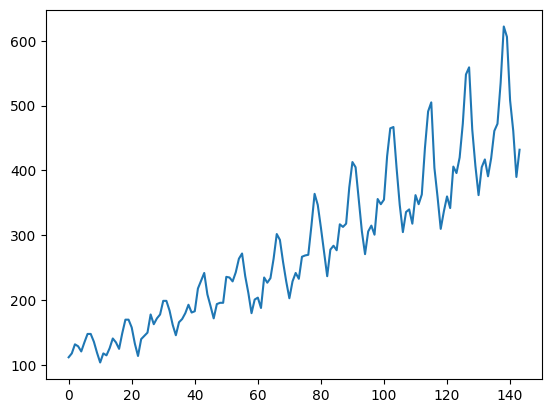

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

dataset = pd.read_csv(url, usecols=[1])

plt.plot(dataset)
plt.show()

In [4]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

In [5]:
# fix random seed for reproducibility
tf.random.set_seed(7)

In [7]:
import pandas as pd

# Load dataset trực tiếp từ URL
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

dataframe = pd.read_csv(url, usecols=[1])

dataset = dataframe.values
dataset = dataset.astype('float32')

print(dataset.shape)
print(dataset[:5])

(144, 1)
[[112.]
 [118.]
 [132.]
 [129.]
 [121.]]


In [8]:
# normalize the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

In [9]:
# split into train and test sets
train_size = int(len(dataset) * 0.67)
test_size = len(dataset) - train_size
train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]
print(len(train), len(test))

96 48


In [15]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1):
	dataX, dataY = [], []
	for i in range(len(dataset)-look_back-1):
		a = dataset[i:(i+look_back), 0]
		dataX.append(a)
		dataY.append(dataset[i + look_back, 0])
	return np.array(dataX), np.array(dataY)

In [16]:

# reshape into X=t and Y=t+1
look_back = 1
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

In [17]:

# reshape input to be [samples, time steps, features]
trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1]))
testX = np.reshape(testX, (testX.shape[0], 1, testX.shape[1]))

In [18]:
# create and fit the LSTM network
model = Sequential()
model.add(LSTM(4, input_shape=(1, look_back)))
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam')
model.fit(trainX, trainY, epochs=100, batch_size=1, verbose=2)

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


94/94 - 2s - 20ms/step - loss: 0.0527
Epoch 2/100
94/94 - 0s - 2ms/step - loss: 0.0284
Epoch 3/100
94/94 - 0s - 2ms/step - loss: 0.0201
Epoch 4/100
94/94 - 0s - 2ms/step - loss: 0.0174
Epoch 5/100
94/94 - 0s - 2ms/step - loss: 0.0160
Epoch 6/100
94/94 - 0s - 2ms/step - loss: 0.0149
Epoch 7/100
94/94 - 0s - 2ms/step - loss: 0.0138
Epoch 8/100
94/94 - 0s - 2ms/step - loss: 0.0127
Epoch 9/100
94/94 - 0s - 3ms/step - loss: 0.0115
Epoch 10/100
94/94 - 0s - 2ms/step - loss: 0.0104
Epoch 11/100
94/94 - 0s - 2ms/step - loss: 0.0093
Epoch 12/100
94/94 - 0s - 2ms/step - loss: 0.0081
Epoch 13/100
94/94 - 0s - 2ms/step - loss: 0.0071
Epoch 14/100
94/94 - 0s - 2ms/step - loss: 0.0061
Epoch 15/100
94/94 - 0s - 2ms/step - loss: 0.0052
Epoch 16/100
94/94 - 0s - 2ms/step - loss: 0.0044
Epoch 17/100
94/94 - 0s - 2ms/step - loss: 0.0038
Epoch 18/100
94/94 - 0s - 2ms/step - loss: 0.0032
Epoch 19/100
94/94 - 0s - 3ms/step - loss: 0.0028
Epoch 20/100
94/94 - 0s - 2ms/step - loss: 0.0025
Epoch 21/100
94/94 -

In [19]:

# make predictions
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)
# invert predictions
trainPredict = scaler.inverse_transform(trainPredict)
trainY = scaler.inverse_transform([trainY])
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform([testY])
# calculate root mean squared error
trainScore = np.sqrt(mean_squared_error(trainY[0], trainPredict[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = np.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
print('Test Score: %.2f RMSE' % (testScore))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 236ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
Train Score: 22.69 RMSE
Test Score: 52.36 RMSE


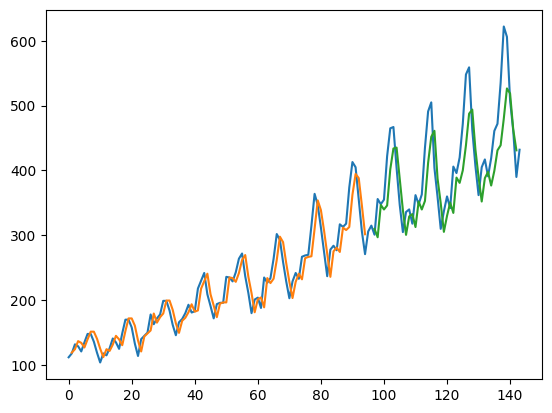

In [20]:

# shift train predictions for plotting
trainPredictPlot = np.empty_like(dataset)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[look_back:len(trainPredict)+look_back, :] = trainPredict
# shift test predictions for plotting
testPredictPlot = np.empty_like(dataset)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(trainPredict)+(look_back*2)+1:len(dataset)-1, :] = testPredict
# plot baseline and predictions
plt.plot(scaler.inverse_transform(dataset))
plt.plot(trainPredictPlot)
plt.plot(testPredictPlot)
plt.show()

Dataset loaded successfully
Dataset shape: (144, 1)
Train X: (95, 1, 1)
Train Y: (95,)
Test X: (48, 1, 1)
Test Y: (48,)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 4)              │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101 (404.00 B)

 Trainable params: 101 (404.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
95/95 - 2s - 19ms/step - loss: 0.0690
Epoch 2/100
95/95 - 0s - 3ms/step - loss: 0.0325
Epoch 3/100
95/95 - 0s - 3ms/step - loss: 0.0290
Epoch 4/100
95/95 - 0s - 3ms/step - loss: 0.0279
Epoch 5/100
95/95 - 0s - 2ms/step - loss: 0.0257
Epoch 6/100
95/95 - 0s - 2ms/step - loss: 0.0230
Epoch 7/100
95/95 - 0s - 3ms/step - loss: 0.0203
Epoch 8/100
95/95 - 0s - 2ms/step - loss: 0.0176
Epoch 9/100
95/95 - 0s - 2ms/step - loss: 0.0152
Epoch 10/100
95/95 - 0s - 3ms/step - loss: 0.0130
Epoch 11/100
95/95 - 0s - 2ms/step - loss: 0.0111
Epoch 12/100
95/95 - 0s - 2ms/step - loss: 0.0095
Epoch 13/100
95/95 - 0s - 2ms/step - loss: 0.0083
Epoch 14/100
95/95 - 0s - 2ms/step - loss: 0.0074
Epoch 15/100
95/95 - 0s - 3ms/step - loss: 0.0067
Epoch 16/100
95/95 - 0s - 2ms/step - loss: 0.0063
Epoch 17/100
95/95 - 0s - 2ms/step - loss: 0.0060
Epoch 18/100
95/95 - 0s - 2ms/step - loss: 0.0058
Epoch 19/100
95/95 - 0s - 2ms/step - loss: 0.0057
Epoch 20/100
95/95 - 0s - 2ms/step - loss: 0.0056
Epoch 21

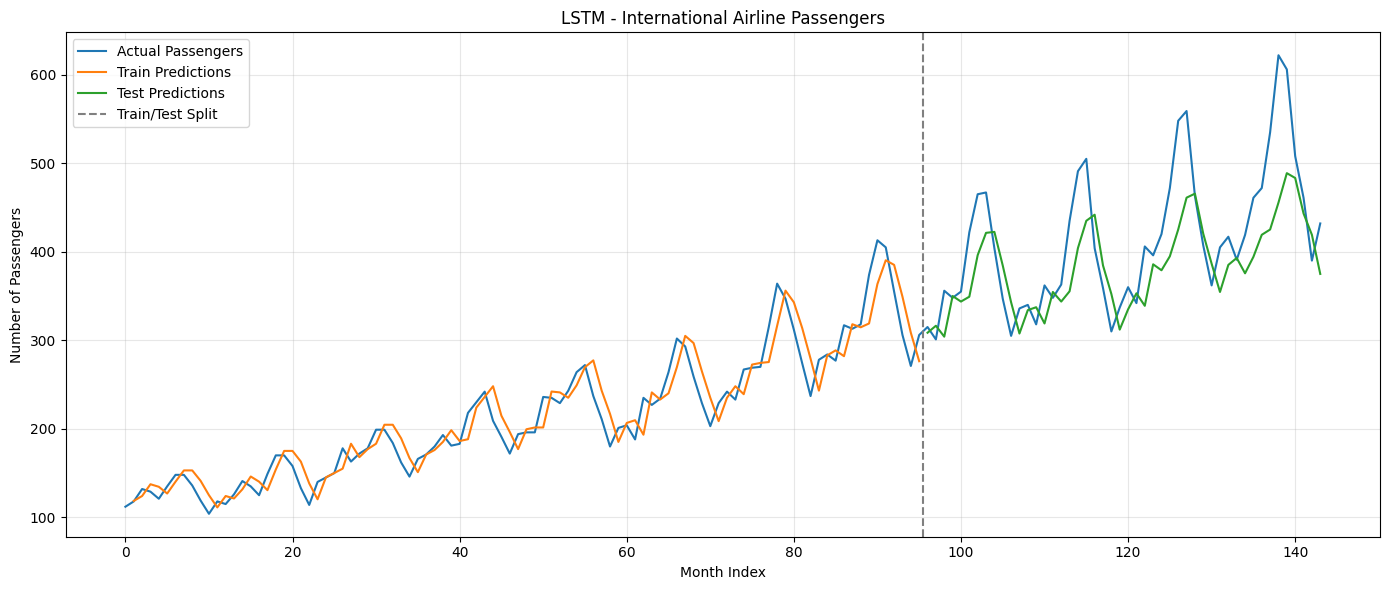

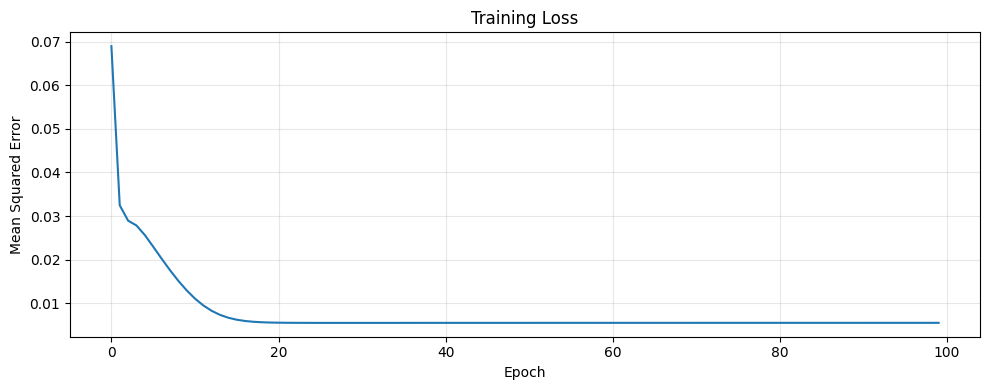


First 10 test predictions:
 Actual  Predicted  Absolute Error
  315.0 308.549988        6.450000
  301.0 316.420013       15.420000
  356.0 304.100006       51.900002
  348.0 350.010010        2.010000
  355.0 343.750000       11.250000
  422.0 349.239990       72.760002
  465.0 396.160004       68.839996
  467.0 421.380005       45.619999
  404.0 422.459991       18.459999
  347.0 384.519989       37.520000

Execution completed successfully!


In [25]:

# LSTM for International Airline Passengers
# Regression Framing - Fixed Google Colab Version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Input
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

# ============================================================
# 1. Fix random seed
# ============================================================

np.random.seed(7)
tf.keras.utils.set_random_seed(7)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

tf.keras.backend.clear_session()

# ============================================================
# 2. Load dataset from URL
# ============================================================

url = (
    "https://raw.githubusercontent.com/"
    "jbrownlee/Datasets/master/airline-passengers.csv"
)

dataframe = pd.read_csv(url)

dataset = dataframe.iloc[:, 1].values.astype("float32")
dataset = dataset.reshape(-1, 1)

print("Dataset loaded successfully")
print("Dataset shape:", dataset.shape)

# ============================================================
# 3. Split train and test BEFORE scaling
# ============================================================

train_size = int(len(dataset) * 0.67)

train_raw = dataset[:train_size]
test_raw = dataset[train_size:]

# ============================================================
# 4. Normalize using training data only
# ============================================================

scaler = MinMaxScaler(feature_range=(0, 1))

train = scaler.fit_transform(train_raw)
test = scaler.transform(test_raw)

# ============================================================
# 5. Convert time series to supervised dataset
# ============================================================

def create_dataset(data, look_back=1):
    dataX, dataY = [], []

    for i in range(len(data) - look_back):
        X = data[i:i + look_back, 0]
        Y = data[i + look_back, 0]

        dataX.append(X)
        dataY.append(Y)

    return np.array(dataX), np.array(dataY)


look_back = 1

trainX, trainY = create_dataset(train, look_back)

# Use the final training observation as context for test
test_context = np.concatenate(
    (train[-look_back:], test),
    axis=0
)

testX, testY = create_dataset(test_context, look_back)

# ============================================================
# 6. Reshape input for LSTM
# Shape: [samples, time steps, features]
# ============================================================

trainX = trainX.reshape(-1, look_back, 1)
testX = testX.reshape(-1, look_back, 1)

print("Train X:", trainX.shape)
print("Train Y:", trainY.shape)
print("Test X:", testX.shape)
print("Test Y:", testY.shape)

# ============================================================
# 7. Build LSTM network
# ============================================================

model = Sequential([
    Input(shape=(look_back, 1)),
    LSTM(4),
    Dense(1)
])

model.compile(
    loss="mean_squared_error",
    optimizer="adam"
)

model.summary()

# ============================================================
# 8. Train model
# ============================================================

history = model.fit(
    trainX,
    trainY,
    epochs=100,
    batch_size=1,
    verbose=2,
    shuffle=False
)

# ============================================================
# 9. Make predictions
# ============================================================

trainPredict = model.predict(trainX, verbose=0)
testPredict = model.predict(testX, verbose=0)

# ============================================================
# 10. Invert scaling
# ============================================================

trainPredict = scaler.inverse_transform(trainPredict)
testPredict = scaler.inverse_transform(testPredict)

trainY_original = scaler.inverse_transform(
    trainY.reshape(-1, 1)
)

testY_original = scaler.inverse_transform(
    testY.reshape(-1, 1)
)

# ============================================================
# 11. Calculate RMSE
# ============================================================

trainScore = np.sqrt(
    mean_squared_error(
        trainY_original[:, 0],
        trainPredict[:, 0]
    )
)

testScore = np.sqrt(
    mean_squared_error(
        testY_original[:, 0],
        testPredict[:, 0]
    )
)

print("\nTrain Score: %.2f RMSE" % trainScore)
print("Test Score:  %.2f RMSE" % testScore)

# ============================================================
# 12. Shift predictions for plotting
# ============================================================

trainPredictPlot = np.full_like(dataset, np.nan)
testPredictPlot = np.full_like(dataset, np.nan)

# Train predictions
trainPredictPlot[
    look_back:look_back + len(trainPredict), 0
] = trainPredict[:, 0]

# Test predictions
test_start = train_size

testPredictPlot[
    test_start:test_start + len(testPredict), 0
] = testPredict[:, 0]

# ============================================================
# 13. Plot actual and predicted values
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(dataset[:, 0], label="Actual Passengers")
plt.plot(trainPredictPlot[:, 0], label="Train Predictions")
plt.plot(testPredictPlot[:, 0], label="Test Predictions")

plt.axvline(
    x=train_size - 0.5,
    linestyle="--",
    color="gray",
    label="Train/Test Split"
)

plt.title("LSTM - International Airline Passengers")
plt.xlabel("Month Index")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 14. Plot training loss
# ============================================================

plt.figure(figsize=(10, 4))

plt.plot(history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 15. Display test predictions
# ============================================================

results = pd.DataFrame({
    "Actual": testY_original[:, 0],
    "Predicted": testPredict[:, 0]
})

results["Absolute Error"] = np.abs(
    results["Actual"] - results["Predicted"]
)

print("\nFirst 10 test predictions:")
print(results.head(10).round(2).to_string(index=False))

print("\nExecution completed successfully!")


trainX shape: (92, 3, 1)
trainY shape: (92,)
testX shape: (44, 3, 1)
testY shape: (44,)
Epoch 1/100
92/92 - 2s - 20ms/step - loss: 0.0579
Epoch 2/100
92/92 - 0s - 3ms/step - loss: 0.0235
Epoch 3/100
92/92 - 0s - 3ms/step - loss: 0.0176
Epoch 4/100
92/92 - 0s - 3ms/step - loss: 0.0154
Epoch 5/100
92/92 - 0s - 3ms/step - loss: 0.0135
Epoch 6/100
92/92 - 0s - 3ms/step - loss: 0.0116
Epoch 7/100
92/92 - 0s - 3ms/step - loss: 0.0099
Epoch 8/100
92/92 - 0s - 3ms/step - loss: 0.0084
Epoch 9/100
92/92 - 0s - 3ms/step - loss: 0.0071
Epoch 10/100
92/92 - 0s - 3ms/step - loss: 0.0061
Epoch 11/100
92/92 - 0s - 3ms/step - loss: 0.0054
Epoch 12/100
92/92 - 0s - 3ms/step - loss: 0.0049
Epoch 13/100
92/92 - 0s - 3ms/step - loss: 0.0046
Epoch 14/100
92/92 - 0s - 3ms/step - loss: 0.0045
Epoch 15/100
92/92 - 0s - 3ms/step - loss: 0.0044
Epoch 16/100
92/92 - 0s - 3ms/step - loss: 0.0043
Epoch 17/100
92/92 - 0s - 2ms/step - loss: 0.0043
Epoch 18/100
92/92 - 0s - 3ms/step - loss: 0.0042
Epoch 19/100
92/92 -

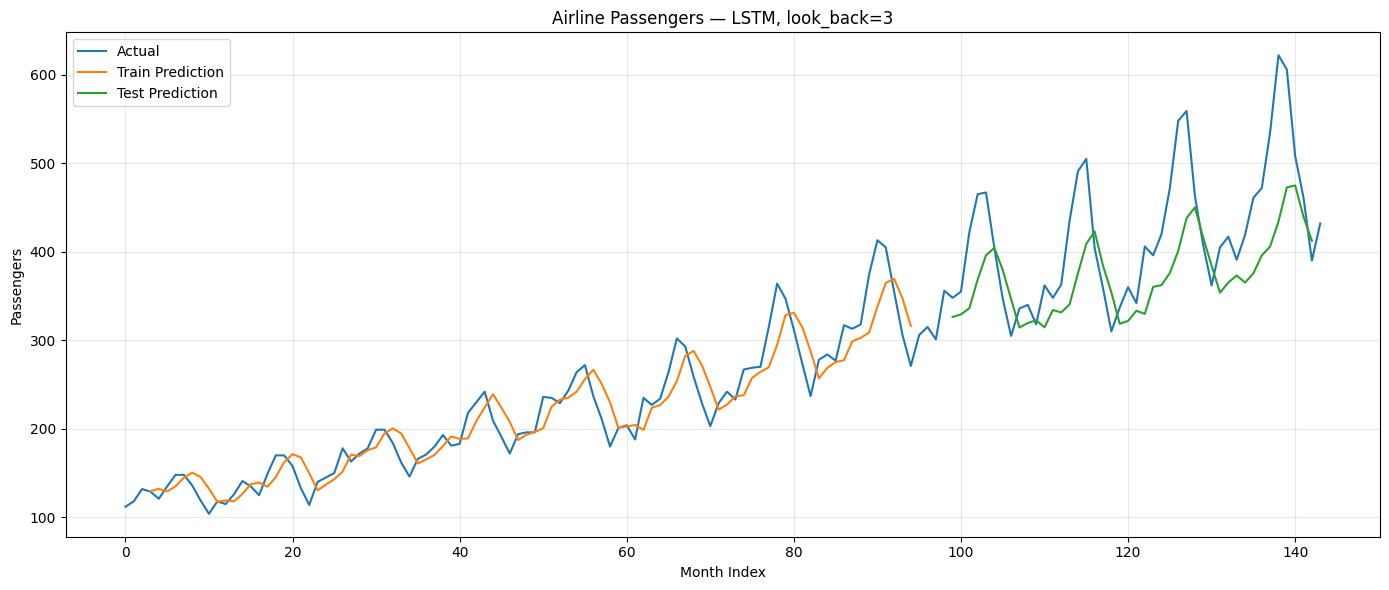

In [28]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

# Fix random seed
np.random.seed(7)
tf.random.set_seed(7)

# Load dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
dataframe = pd.read_csv(url, usecols=[1])

dataset = dataframe.values.astype("float32")

# Normalize dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

# Split train/test
train_size = int(len(dataset) * 0.67)
train = dataset[:train_size, :]
test = dataset[train_size:, :]

# Create dataset matrix: preserve original tutorial indexing
def create_dataset(dataset, look_back=1):
    dataX, dataY = [], []

    for i in range(len(dataset) - look_back - 1):
        dataX.append(dataset[i:i + look_back, 0])
        dataY.append(dataset[i + look_back, 0])

    return np.array(dataX), np.array(dataY)

# Window size
look_back = 3

trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

# Reshape to [samples, time steps, features]
trainX = trainX.reshape(trainX.shape[0], look_back, 1)
testX = testX.reshape(testX.shape[0], look_back, 1)

print("trainX shape:", trainX.shape)
print("trainY shape:", trainY.shape)
print("testX shape:", testX.shape)
print("testY shape:", testY.shape)

# Build model
model = Sequential([
    Input(shape=(look_back, 1)),
    LSTM(4),
    Dense(1)
])

model.compile(loss="mean_squared_error", optimizer="adam")

# Train model
model.fit(
    trainX,
    trainY,
    epochs=100,
    batch_size=1,
    verbose=2
)

# Predictions
trainPredict = model.predict(trainX, verbose=0)
testPredict = model.predict(testX, verbose=0)

# Inverse normalization
trainPredict = scaler.inverse_transform(trainPredict)
testPredict = scaler.inverse_transform(testPredict)

trainY_original = scaler.inverse_transform(trainY.reshape(-1, 1))
testY_original = scaler.inverse_transform(testY.reshape(-1, 1))

# RMSE
trainScore = np.sqrt(
    mean_squared_error(trainY_original, trainPredict)
)
testScore = np.sqrt(
    mean_squared_error(testY_original, testPredict)
)

print(f"Train Score: {trainScore:.2f} RMSE")
print(f"Test Score: {testScore:.2f} RMSE")

# Plot train predictions
trainPredictPlot = np.full_like(dataset, np.nan)
trainPredictPlot[
    look_back:look_back + len(trainPredict), 0
] = trainPredict[:, 0]

# Plot test predictions using original tutorial alignment
testPredictPlot = np.full_like(dataset, np.nan)
test_start = len(trainPredict) + (look_back * 2) + 1
test_end = test_start + len(testPredict)

if test_end <= len(dataset):
    testPredictPlot[test_start:test_end, 0] = testPredict[:, 0]

# Plot
plt.figure(figsize=(14, 6))
plt.plot(scaler.inverse_transform(dataset), label="Actual")
plt.plot(trainPredictPlot, label="Train Prediction")
plt.plot(testPredictPlot, label="Test Prediction")
plt.title("Airline Passengers — LSTM, look_back=3")
plt.xlabel("Month Index")
plt.ylabel("Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [29]:
# reshape input to be [samples, time steps, features]
trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1))
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

Upload airline-passengers.csv


Saving airline-passengers.csv to airline-passengers.csv
Dataset shape: (144, 1)
   Passengers
0         112
1         118
2         132
3         129
4         121
trainX shape: (92, 3, 1)
trainY shape: (92,)
testX shape: (44, 3, 1)
testY shape: (44,)
Epoch 1/100
92/92 - 2s - 22ms/step - loss: 0.0422
Epoch 2/100
92/92 - 1s - 7ms/step - loss: 0.0172
Epoch 3/100
92/92 - 0s - 4ms/step - loss: 0.0128
Epoch 4/100
92/92 - 0s - 4ms/step - loss: 0.0115
Epoch 5/100
92/92 - 0s - 3ms/step - loss: 0.0103
Epoch 6/100
92/92 - 0s - 3ms/step - loss: 0.0092
Epoch 7/100
92/92 - 0s - 3ms/step - loss: 0.0082
Epoch 8/100
92/92 - 0s - 2ms/step - loss: 0.0072
Epoch 9/100
92/92 - 0s - 3ms/step - loss: 0.0064
Epoch 10/100
92/92 - 0s - 3ms/step - loss: 0.0058
Epoch 11/100
92/92 - 0s - 3ms/step - loss: 0.0053
Epoch 12/100
92/92 - 0s - 3ms/step - loss: 0.0050
Epoch 13/100
92/92 - 0s - 3ms/step - loss: 0.0048
Epoch 14/100
92/92 - 0s - 3ms/step - loss: 0.0046
Epoch 15/100
92/92 - 0s - 3ms/step - loss: 0.0045
Epoch 

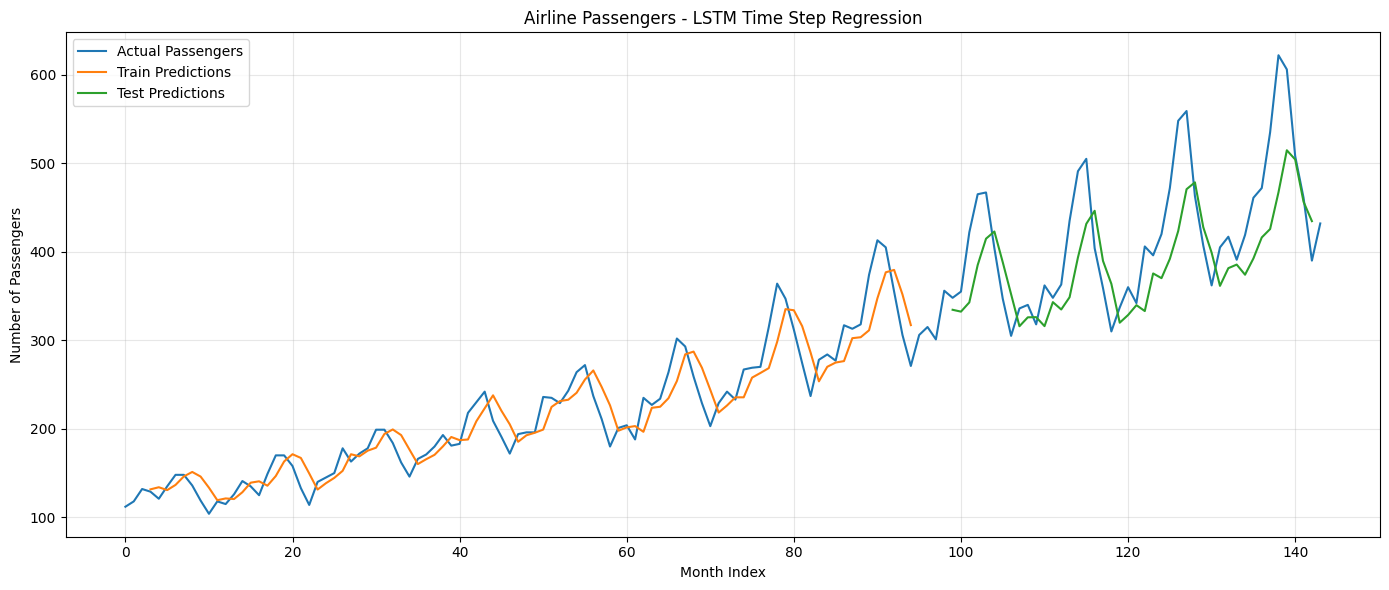

In [33]:

# LSTM for international airline passengers
# Time step regression framing

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

from google.colab import files
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

# 1. Fix random seed
np.random.seed(7)
tf.random.set_seed(7)

# 2. Upload dataset
print("Upload airline-passengers.csv")
uploaded = files.upload()

if "airline-passengers.csv" in uploaded:
    dataframe = pd.read_csv("airline-passengers.csv", usecols=[1])
elif len(uploaded) > 0:
    filename = next(iter(uploaded))
    print(f"Using uploaded file: {filename}")
    dataframe = pd.read_csv(filename, usecols=[1])
else:
    print("No file uploaded. Downloading dataset from GitHub...")
    url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
    dataframe = pd.read_csv(url, usecols=[1])

dataset = dataframe.values.astype("float32")

print("Dataset shape:", dataset.shape)
print(dataframe.head())

# 3. Normalize dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

# 4. Split into train and test sets
train_size = int(len(dataset) * 0.67)

train = dataset[:train_size, :]
test = dataset[train_size:, :]

# 5. Convert array into dataset matrix
def create_dataset(dataset, look_back=1):
    dataX, dataY = [], []

    for i in range(len(dataset) - look_back - 1):
        a = dataset[i:i + look_back, 0]
        dataX.append(a)
        dataY.append(dataset[i + look_back, 0])

    return np.array(dataX), np.array(dataY)

# 6. Use 3 time steps to predict the next value
look_back = 3

trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

# 7. Reshape to [samples, time steps, features]
trainX = trainX.reshape(trainX.shape[0], look_back, 1)
testX = testX.reshape(testX.shape[0], look_back, 1)

print("trainX shape:", trainX.shape)
print("trainY shape:", trainY.shape)
print("testX shape:", testX.shape)
print("testY shape:", testY.shape)

# 8. Create and train LSTM model
model = Sequential([
    Input(shape=(look_back, 1)),
    LSTM(4),
    Dense(1)
])

model.compile(
    loss="mean_squared_error",
    optimizer="adam"
)

model.fit(
    trainX,
    trainY,
    epochs=100,
    batch_size=1,
    verbose=2
)

# 9. Make predictions
trainPredict = model.predict(trainX, verbose=0)
testPredict = model.predict(testX, verbose=0)

# 10. Invert normalization
trainPredict = scaler.inverse_transform(trainPredict)
testPredict = scaler.inverse_transform(testPredict)

trainY_original = scaler.inverse_transform(
    trainY.reshape(-1, 1)
)
testY_original = scaler.inverse_transform(
    testY.reshape(-1, 1)
)

# 11. Calculate RMSE
trainScore = np.sqrt(
    mean_squared_error(trainY_original, trainPredict)
)
testScore = np.sqrt(
    mean_squared_error(testY_original, testPredict)
)

print(f"Train Score: {trainScore:.2f} RMSE")
print(f"Test Score: {testScore:.2f} RMSE")

# 12. Prepare predictions for plotting
trainPredictPlot = np.full_like(dataset, np.nan)

train_start = look_back
train_end = train_start + len(trainPredict)

trainPredictPlot[train_start:train_end, 0] = trainPredict[:, 0]

testPredictPlot = np.full_like(dataset, np.nan)

# Predictions correspond to the test portion
test_start = train_size + look_back
test_end = test_start + len(testPredict)

if test_end <= len(dataset):
    testPredictPlot[test_start:test_end, 0] = testPredict[:, 0]

# 13. Plot actual values and predictions
actual = scaler.inverse_transform(dataset)

plt.figure(figsize=(14, 6))
plt.plot(actual, label="Actual Passengers")
plt.plot(trainPredictPlot, label="Train Predictions")
plt.plot(testPredictPlot, label="Test Predictions")

plt.title("Airline Passengers - LSTM Time Step Regression")
plt.xlabel("Month Index")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


LSTM with Memory Between Batches


Upload airline-passengers.csv


Saving airline-passengers.csv to airline-passengers (3).csv
Dataset shape: (144, 1)
trainX shape: (92, 3, 1)
testX shape: (44, 3, 1)
Completed epoch 10/100
Completed epoch 20/100
Completed epoch 30/100
Completed epoch 40/100
Completed epoch 50/100
Completed epoch 60/100
Completed epoch 70/100
Completed epoch 80/100
Completed epoch 90/100
Completed epoch 100/100
Training completed.
Train Score: 22.07 RMSE
Test Score: 52.40 RMSE


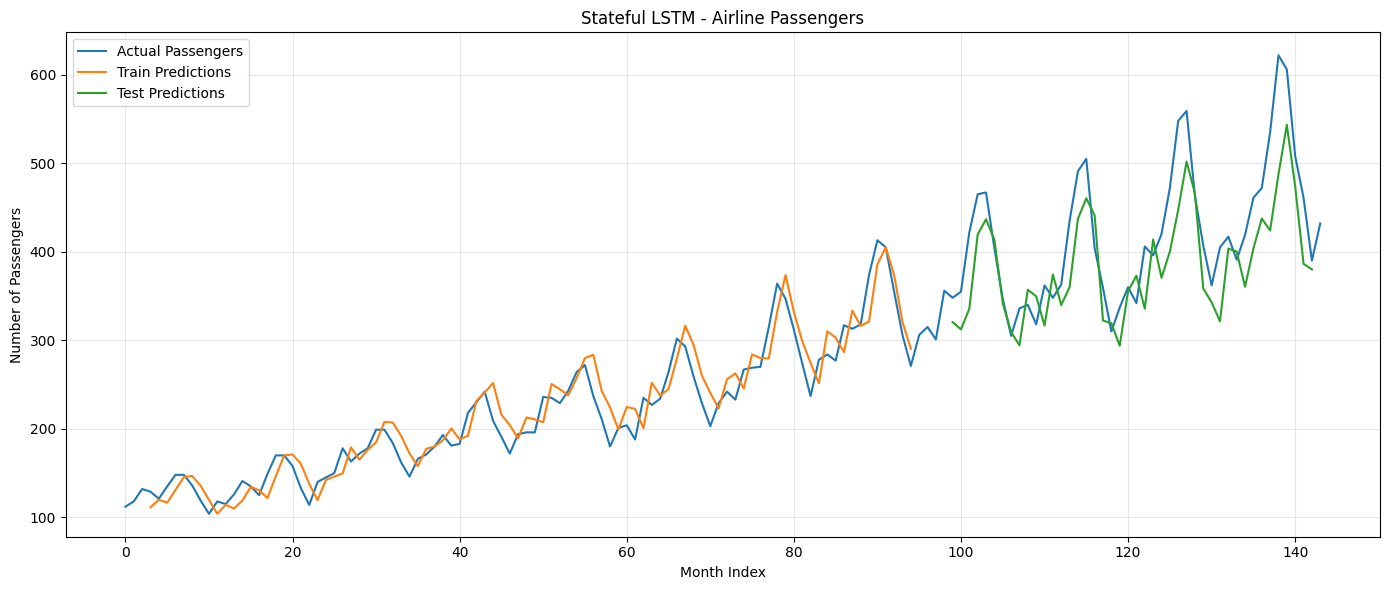

In [39]:

# LSTM for International Airline Passengers Problem with Memory
# Compatible with Google Colab / Keras 3

import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

# --------------------------------------------------
# 1. Load dataset
# --------------------------------------------------

print("Upload airline-passengers.csv")
uploaded = files.upload()

if len(uploaded) > 0:
    filename = next(
        (name for name in uploaded if name.startswith("airline-passengers")),
        next(iter(uploaded))
    )
    dataframe = pd.read_csv(filename, usecols=[1])
else:
    url = (
        "https://raw.githubusercontent.com/"
        "jbrownlee/Datasets/master/airline-passengers.csv"
    )
    dataframe = pd.read_csv(url, usecols=[1])

dataset = dataframe.values.astype("float32")

print("Dataset shape:", dataset.shape)

# --------------------------------------------------
# 2. Normalize dataset
# --------------------------------------------------

scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

# --------------------------------------------------
# 3. Split into train and test sets
# --------------------------------------------------

train_size = int(len(dataset) * 0.67)
test_size = len(dataset) - train_size

train = dataset[0:train_size, :]
test = dataset[train_size:len(dataset), :]

# --------------------------------------------------
# 4. Convert array into dataset matrix
# --------------------------------------------------

def create_dataset(dataset, look_back=1):
    dataX, dataY = [], []

    for i in range(len(dataset) - look_back - 1):
        a = dataset[i:(i + look_back), 0]
        dataX.append(a)
        dataY.append(dataset[i + look_back, 0])

    return np.array(dataX), np.array(dataY)


look_back = 3

trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

# Reshape input to [samples, time steps, features]
trainX = np.reshape(
    trainX, (trainX.shape[0], look_back, 1)
)
testX = np.reshape(
    testX, (testX.shape[0], look_back, 1)
)

print("trainX shape:", trainX.shape)
print("testX shape:", testX.shape)

# --------------------------------------------------
# 5. Create and fit Stateful LSTM network
# --------------------------------------------------

batch_size = 1

model = Sequential([
    Input(batch_shape=(batch_size, look_back, 1)),
    LSTM(4, stateful=True),
    Dense(1)
])

model.compile(
    loss="mean_squared_error",
    optimizer="adam"
)

# Keras 3: reset the state on the LSTM layer,
# not on the Sequential model.
def reset_lstm_state():
    model.layers[0].reset_states()


for epoch in range(100):
    model.fit(
        trainX,
        trainY,
        epochs=1,
        batch_size=batch_size,
        verbose=0,
        shuffle=False
    )

    # Reset recurrent state between epochs
    reset_lstm_state()

    if (epoch + 1) % 10 == 0:
        print(f"Completed epoch {epoch + 1}/100")

print("Training completed.")

# --------------------------------------------------
# 6. Make predictions
# --------------------------------------------------

# Reset before predicting the training set
reset_lstm_state()

trainPredict = model.predict(
    trainX,
    batch_size=batch_size,
    verbose=0
)

# Reset state between train and test predictions
reset_lstm_state()

testPredict = model.predict(
    testX,
    batch_size=batch_size,
    verbose=0
)

# --------------------------------------------------
# 7. Invert predictions to original scale
# --------------------------------------------------

trainPredict = scaler.inverse_transform(trainPredict)
trainY_original = scaler.inverse_transform(
    trainY.reshape(-1, 1)
)

testPredict = scaler.inverse_transform(testPredict)
testY_original = scaler.inverse_transform(
    testY.reshape(-1, 1)
)

# --------------------------------------------------
# 8. Calculate root mean squared error
# --------------------------------------------------

trainScore = math.sqrt(
    mean_squared_error(trainY_original, trainPredict)
)
print("Train Score: %.2f RMSE" % trainScore)

testScore = math.sqrt(
    mean_squared_error(testY_original, testPredict)
)
print("Test Score: %.2f RMSE" % testScore)

# --------------------------------------------------
# 9. Prepare predictions for plotting
# --------------------------------------------------

trainPredictPlot = np.full_like(dataset, np.nan)
testPredictPlot = np.full_like(dataset, np.nan)

# Align training predictions with their target months
train_start = look_back
train_end = train_start + len(trainPredict)

trainPredictPlot[train_start:train_end, :] = trainPredict

# Align test predictions with their target months
test_start = train_size + look_back
test_end = test_start + len(testPredict)

testPredictPlot[test_start:test_end, :] = testPredict

# --------------------------------------------------
# 10. Plot baseline and predictions
# --------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    scaler.inverse_transform(dataset),
    label="Actual Passengers"
)

plt.plot(
    trainPredictPlot,
    label="Train Predictions"
)

plt.plot(
    testPredictPlot,
    label="Test Predictions"
)

plt.title("Stateful LSTM - Airline Passengers")
plt.xlabel("Month Index")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Stacked LSTMs with Memory Between Batches


In [42]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

batch_size = 1
look_back = 3

model = Sequential()

# Khai báo batch shape cố định cho Stateful LSTM
model.add(Input(batch_shape=(batch_size, look_back, 1)))

# LSTM layer 1: trả về toàn bộ chuỗi đầu ra
model.add(
    LSTM(
        4,
        stateful=True,
        return_sequences=True
    )
)

# LSTM layer 2: nhận chuỗi đầu ra từ layer 1
model.add(
    LSTM(
        4,
        stateful=True
    )
)

# Output layer
model.add(Dense(1))

model.compile(
    loss="mean_squared_error",
    optimizer="adam"
)

model.summary()


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_11 (LSTM)                  │ (1, 3, 4)              │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_12 (LSTM)                  │ (1, 4)                 │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (1, 1)                 │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 245 (980.00 B)

 Trainable params: 245 (980.00 B)

 Non-trainable params: 0 (0.00 B)

Upload airline-passengers.csv


Saving airline-passengers.csv to airline-passengers (6).csv
Dataset shape: (144, 1)
trainX shape: (92, 3, 1)
testX shape: (44, 3, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (1, 3, 4)              │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (1, 4)                 │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 1)                 │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 245 (980.00 B)

 Trainable params: 245 (980.00 B)

 Non-trainable params: 0 (0.00 B)

92/92 - 4s - 46ms/step - loss: 0.0049
92/92 - 0s - 4ms/step - loss: 0.0112
92/92 - 0s - 4ms/step - loss: 0.0073
92/92 - 0s - 4ms/step - loss: 0.0062
92/92 - 0s - 4ms/step - loss: 0.0058
92/92 - 0s - 4ms/step - loss: 0.0058
92/92 - 0s - 4ms/step - loss: 0.0058
92/92 - 0s - 4ms/step - loss: 0.0058
92/92 - 0s - 4ms/step - loss: 0.0058
92/92 - 0s - 3ms/step - loss: 0.0058
92/92 - 0s - 4ms/step - loss: 0.0058
92/92 - 0s - 4ms/step - loss: 0.0058
92/92 - 0s - 3ms/step - loss: 0.0057
92/92 - 0s - 4ms/step - loss: 0.0057
92/92 - 0s - 4ms/step - loss: 0.0057
92/92 - 0s - 4ms/step - loss: 0.0057
92/92 - 0s - 4ms/step - loss: 0.0057
92/92 - 0s - 4ms/step - loss: 0.0057
92/92 - 0s - 4ms/step - loss: 0.0057
92/92 - 0s - 4ms/step - loss: 0.0057
92/92 - 0s - 4ms/step - loss: 0.0057
92/92 - 0s - 4ms/step - loss: 0.0056
92/92 - 0s - 4ms/step - loss: 0.0056
92/92 - 0s - 4ms/step - loss: 0.0056
92/92 - 0s - 4ms/step - loss: 0.0056
92/92 - 1s - 6ms/step - loss: 0.0056
92/92 - 1s - 6ms/step - loss: 0.0056


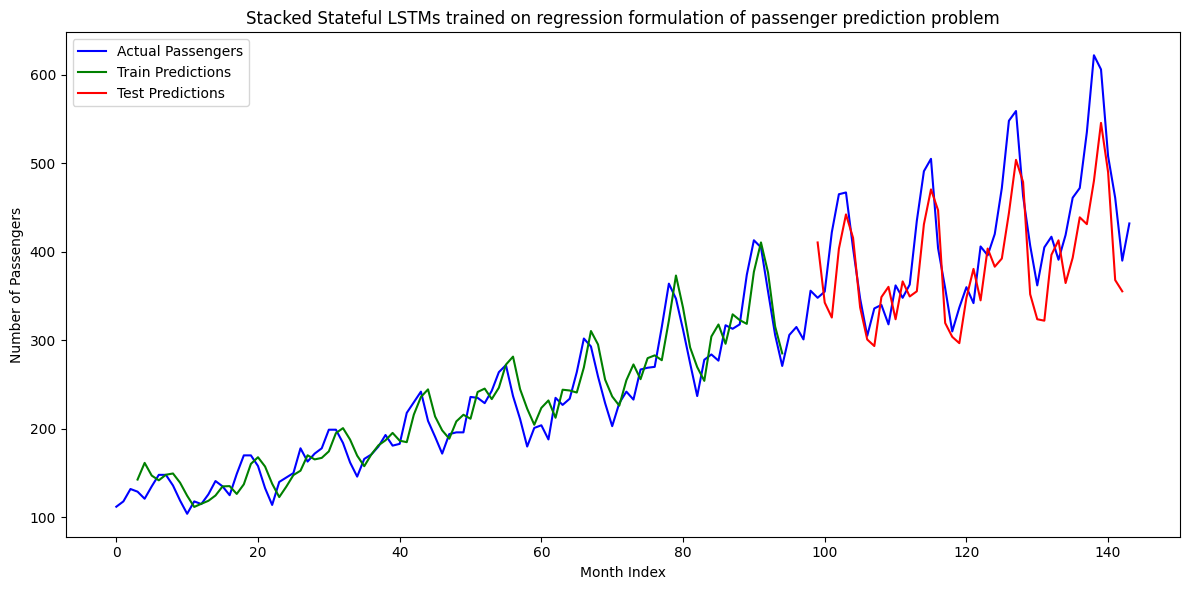

In [46]:

# Stacked LSTM for International Airline Passengers Problem with Memory
# Google Colab / Keras 3

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

from google.colab import files
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

# --------------------------------------------------
# 1. Create dataset matrix
# --------------------------------------------------

def create_dataset(dataset, look_back=1):
    dataX, dataY = [], []

    for i in range(len(dataset) - look_back - 1):
        a = dataset[i:(i + look_back), 0]
        dataX.append(a)
        dataY.append(dataset[i + look_back, 0])

    return np.array(dataX), np.array(dataY)


# --------------------------------------------------
# 2. Fix random seeds
# --------------------------------------------------

tf.keras.backend.clear_session()
tf.random.set_seed(7)
np.random.seed(7)

# --------------------------------------------------
# 3. Load dataset
# --------------------------------------------------

print("Upload airline-passengers.csv")
uploaded = files.upload()

if uploaded:
    filename = next(
        (
            name for name in uploaded
            if name.startswith("airline-passengers")
        ),
        next(iter(uploaded))
    )
    dataframe = pd.read_csv(filename, usecols=[1])
else:
    url = (
        "https://raw.githubusercontent.com/"
        "jbrownlee/Datasets/master/airline-passengers.csv"
    )
    dataframe = pd.read_csv(url, usecols=[1])

dataset = dataframe.values.astype("float32")
print("Dataset shape:", dataset.shape)

# --------------------------------------------------
# 4. Normalize dataset
# --------------------------------------------------

scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

# --------------------------------------------------
# 5. Split into train and test sets
# --------------------------------------------------

train_size = int(len(dataset) * 0.67)

train = dataset[:train_size, :]
test = dataset[train_size:, :]

# --------------------------------------------------
# 6. Prepare sequences
# --------------------------------------------------

look_back = 3

trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

trainX = trainX.reshape(trainX.shape[0], look_back, 1)
testX = testX.reshape(testX.shape[0], look_back, 1)

print("trainX shape:", trainX.shape)
print("testX shape:", testX.shape)

# --------------------------------------------------
# 7. Build Stacked Stateful LSTM
# --------------------------------------------------

batch_size = 1

model = Sequential([
    Input(batch_shape=(batch_size, look_back, 1)),
    LSTM(4, stateful=True, return_sequences=True),
    LSTM(4, stateful=True),
    Dense(1)
])

model.compile(
    loss="mean_squared_error",
    optimizer="adam"
)

model.summary()


def reset_lstm_states():
    for layer in model.layers:
        if isinstance(layer, LSTM):
            layer.reset_states()


# --------------------------------------------------
# 8. Train for 100 epochs
# --------------------------------------------------

for epoch in range(100):
    model.fit(
        trainX,
        trainY,
        epochs=1,
        batch_size=batch_size,
        verbose=2,
        shuffle=False
    )

    # Reset both LSTM layers between epochs
    reset_lstm_states()

# --------------------------------------------------
# 9. Make predictions
# --------------------------------------------------

reset_lstm_states()

trainPredict = model.predict(
    trainX,
    batch_size=batch_size,
    verbose=0
)

reset_lstm_states()

testPredict = model.predict(
    testX,
    batch_size=batch_size,
    verbose=0
)

# --------------------------------------------------
# 10. Invert predictions to original scale
# --------------------------------------------------

trainPredict = scaler.inverse_transform(trainPredict)
trainY_original = scaler.inverse_transform(
    trainY.reshape(-1, 1)
)

testPredict = scaler.inverse_transform(testPredict)
testY_original = scaler.inverse_transform(
    testY.reshape(-1, 1)
)

# --------------------------------------------------
# 11. Calculate RMSE
# --------------------------------------------------

trainScore = np.sqrt(
    mean_squared_error(trainY_original, trainPredict)
)
print("Train Score: %.2f RMSE" % trainScore)

testScore = np.sqrt(
    mean_squared_error(testY_original, testPredict)
)
print("Test Score: %.2f RMSE" % testScore)

# --------------------------------------------------
# 12. Shift predictions for plotting (original tutorial)
# --------------------------------------------------

trainPredictPlot = np.empty_like(dataset)
trainPredictPlot[:, :] = np.nan

trainPredictPlot[
    look_back:len(trainPredict) + look_back, :
] = trainPredict

testPredictPlot = np.empty_like(dataset)
testPredictPlot[:, :] = np.nan

test_start = len(trainPredict) + (look_back * 2) + 1
test_end = len(dataset) - 1

testPredictPlot[test_start:test_end, :] = testPredict

# --------------------------------------------------
# 13. Plot actual values and predictions
# --------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    scaler.inverse_transform(dataset),
    color="blue",
    label="Actual Passengers"
)

plt.plot(
    trainPredictPlot,
    color="green",
    label="Train Predictions"
)

plt.plot(
    testPredictPlot,
    color="red",
    label="Test Predictions"
)

plt.title(
    "Stacked Stateful LSTMs trained on regression formulation "
    "of passenger prediction problem"
)
plt.xlabel("Month Index")
plt.ylabel("Number of Passengers")
plt.legend()
plt.tight_layout()
plt.show()
